In [4]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import Window

spark = SparkSession.builder.appName("HyderabadTransit").getOrCreate()
print("Spark version:", spark.version)

Spark version: 4.0.4


In [3]:
import os
print(os.listdir("/content"))

['.config', 'routes.txt', 'exports', 'trips.txt', 'stop_times.txt', 'calendar.txt', 'stops.txt', 'sample_data']


In [5]:
files = ["stop_times", "trips", "routes", "stops", "calendar"]

gtfs = {}
for name in files:
    path = f"/content/{name}.txt"
    gtfs[name] = spark.read.csv(path, header=True, inferSchema=True)
    print(f"{name:12s} rows: {gtfs[name].count():>8,}   columns: {gtfs[name].columns}")

stop_times   rows: 1,132,807   columns: ['trip_id', 'stop_sequence', 'stop_id', 'departure_time', 'arrival_time', 'timepoint']
trips        rows:   44,892   columns: ['route_id', 'trip_id', 'service_id', 'direction_id', 'trip_short_name']
routes       rows:    1,031   columns: ['route_id', 'route_long_name', 'agency_id', 'route_type']
stops        rows:    5,028   columns: ['stop_id', 'stop_name', 'zone_id', 'stop_lat', 'stop_lon', 'stop_desc']
calendar     rows:        1   columns: ['service_id', 'start_date', 'end_date', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday']


In [6]:
st = gtfs["stop_times"]
tr = gtfs["trips"]
rt = gtfs["routes"]

trip_stops = (st
    .join(tr.select("trip_id", "route_id", "service_id"), on="trip_id", how="inner")
    .join(rt.select("route_id", "route_long_name"), on="route_id", how="left")
    .select(
        "route_id", "route_long_name", "trip_id", "service_id",
        F.col("stop_sequence").cast("int").alias("stop_seq"),
        "stop_id",
        "departure_time",
        F.split(F.col("departure_time"), ":").getItem(0).cast("int").alias("hour")
    )
)

print("Trip-stop rows:", trip_stops.count())

Trip-stop rows: 1132807


In [14]:
stop_pop = (trip_stops.groupBy("stop_id")
            .agg(F.count("*").alias("trips_at_stop")))

row_avg = (trip_stops.join(stop_pop, on="stop_id", how="left")
           .agg(F.avg("trips_at_stop")).first()[0])
print("Row-weighted average trips per stop:", round(row_avg, 1))

Row-weighted average trips per stop: 1248.6


In [15]:
capacity = 60

# Time-of-day multiplier: commuter peaks higher, late night lower.
# This is an assumption, so state it in your report.
time_mult = (F.when((F.col("hour") % 24).isin(7, 8, 9, 17, 18, 19), 1.5)
              .when((F.col("hour") % 24) < 5, 0.5)
              .otherwise(1.0))

df_real = (trip_stops
    .join(stop_pop, on="stop_id", how="left")
    .withColumn("boardings",
        F.floor(F.rand(seed=42) * 6 * F.col("trips_at_stop") / row_avg * time_mult).cast("int"))
    .withColumn("alightings", F.floor(F.rand(seed=7) * 6).cast("int"))
    .withColumn("capacity", F.lit(capacity))
)

w = (Window.partitionBy("trip_id")
           .orderBy("stop_seq")
           .rowsBetween(Window.unboundedPreceding, Window.currentRow))

df_real = (df_real
    .withColumn("onboard_raw", F.sum(F.col("boardings") - F.col("alightings")).over(w))
    .withColumn("onboard", F.least(F.greatest(F.col("onboard_raw"), F.lit(0)), F.col("capacity")))
    .withColumn("load_factor", F.round(F.col("onboard") / F.col("capacity"), 2))
    .withColumn("overloaded", F.col("load_factor") > 0.85)
)

print("Overloaded stop records:", df_real.filter("overloaded").count())
print("Average load factor:", round(df_real.agg(F.avg("load_factor")).first()[0], 3))

Overloaded stop records: 108074
Average load factor: 0.235


In [9]:
summary_real = (df_real
    .withColumn("hour_of_day", F.col("hour") % 24)
    .groupBy("hour_of_day")
    .agg(
        F.count("*").alias("stop_visits"),
        F.round(F.avg("load_factor"), 3).alias("avg_load_factor"),
        F.sum(F.col("overloaded").cast("int")).alias("overloaded_count")
    )
    .withColumn("overloaded_share",
        F.round(F.col("overloaded_count") / F.col("stop_visits"), 3))
    .orderBy("hour_of_day")
)

summary_real.show(24)

+-----------+-----------+---------------+----------------+----------------+
|hour_of_day|stop_visits|avg_load_factor|overloaded_count|overloaded_share|
+-----------+-----------+---------------+----------------+----------------+
|          0|      33948|          0.275|            4288|           0.126|
|          1|      29752|          0.268|            3660|           0.123|
|          2|      26385|          0.263|            3219|           0.122|
|          3|      23740|          0.251|            2714|           0.114|
|          4|      23510|          0.229|            2446|           0.104|
|          5|      28183|          0.202|            2410|           0.086|
|          6|      37734|          0.176|            2562|           0.068|
|          7|      44704|          0.212|            3628|           0.081|
|          8|      48092|          0.246|            4769|           0.099|
|          9|      50021|          0.265|            5641|           0.113|
|         10

In [10]:
busiest = summary_real.orderBy(F.desc("avg_load_factor")).first()
print(f"Busiest hour: {busiest['hour_of_day']}:00 "
      f"(avg load factor {busiest['avg_load_factor']}, "
      f"{busiest['stop_visits']:,} stop visits)")

Busiest hour: 23:00 (avg load factor 0.281, 39,073 stop visits)


In [11]:
summary_real.toPandas().to_csv("hyderabad_hour_summary.csv", index=False)
print("Saved hyderabad_hour_summary.csv")

Saved hyderabad_hour_summary.csv


In [12]:
trip_stops.groupBy("hour").agg(
    F.countDistinct("trip_id").alias("trips"),
    F.count("*").alias("stop_visits")
).withColumn("stops_per_trip", F.round(F.col("stop_visits") / F.col("trips"), 1)) \
 .orderBy("hour").show(30)

+----+-----+-----------+--------------+
|hour|trips|stop_visits|stops_per_trip|
+----+-----+-----------+--------------+
|   1|    1|          1|           1.0|
|   2|    5|         11|           2.2|
|   3|   72|        256|           3.6|
|   4|  511|       2162|           4.2|
|   5| 1831|       7987|           4.4|
|   6| 4294|      18704|           4.4|
|   7| 6822|      26901|           3.9|
|   8| 9059|      31233|           3.4|
|   9|11177|      34272|           3.1|
|  10|13197|      37066|           2.8|
|  11|15093|      39258|           2.6|
|  12|17060|      42180|           2.5|
|  13|19016|      44766|           2.4|
|  14|21072|      48636|           2.3|
|  15|23019|      52382|           2.3|
|  16|24941|      55067|           2.2|
|  17|26774|      56820|           2.1|
|  18|28407|      58727|           2.1|
|  19|29777|      59877|           2.0|
|  20|30378|      57994|           1.9|
|  21|29792|      51963|           1.7|
|  22|28154|      43142|           1.5|


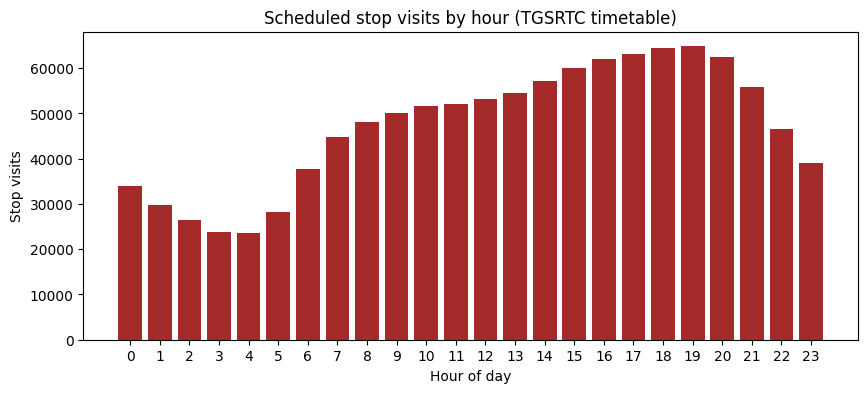

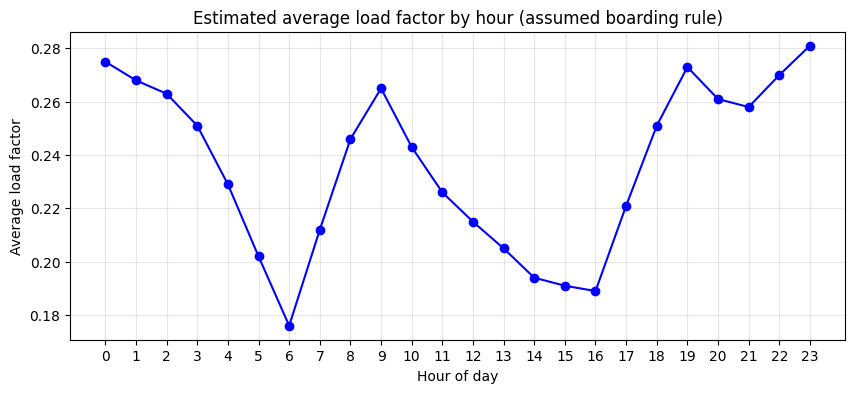

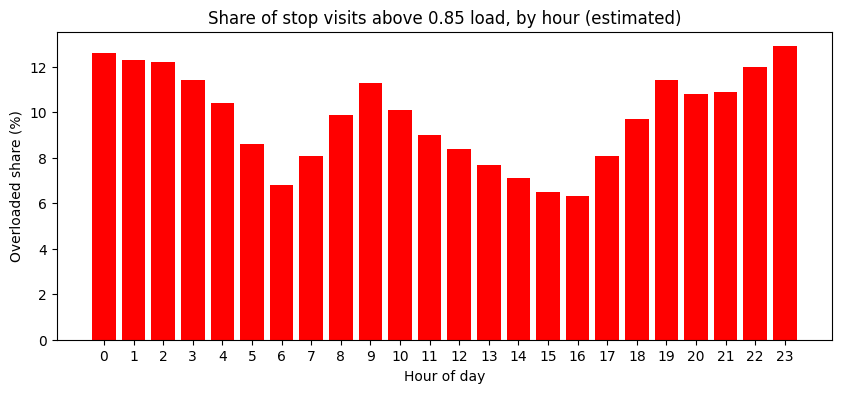

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/hyderabad_hour_summary.csv")

# Chart 1: real timetable pattern
plt.figure(figsize=(10, 4))
plt.bar(df["hour_of_day"], df["stop_visits"], color="brown")
plt.title("Scheduled stop visits by hour (TGSRTC timetable)")
plt.xlabel("Hour of day")
plt.ylabel("Stop visits")
plt.xticks(range(24))
plt.savefig("fig1_stop_visits_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

# Chart 2: estimated load factor by hour
plt.figure(figsize=(10, 4))
plt.plot(df["hour_of_day"], df["avg_load_factor"], marker="o", color="blue")
plt.title("Estimated average load factor by hour (assumed boarding rule)")
plt.xlabel("Hour of day")
plt.ylabel("Average load factor")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.savefig("fig2_avg_load_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

# Chart 3: share of overloaded stop visits by hour
plt.figure(figsize=(10, 4))
plt.bar(df["hour_of_day"], df["overloaded_share"] * 100, color="red")
plt.title("Share of stop visits above 0.85 load, by hour (estimated)")
plt.xlabel("Hour of day")
plt.ylabel("Overloaded share (%)")
plt.xticks(range(24))
plt.savefig("fig3_overloaded_share_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
import matplotlib.pyplot as plt

stop_stats = (df_real.groupBy("stop_id")
    .agg(F.count("*").alias("visits"),
         F.avg("load_factor").alias("avg_load"),
         F.avg(F.col("overloaded").cast("int")).alias("overload_rate"))
    .join(gtfs["stops"].select("stop_id", "stop_name", "stop_lat", "stop_lon"), on="stop_id")
    .toPandas())

print(len(stop_stats), "stops with data")

5028 stops with data


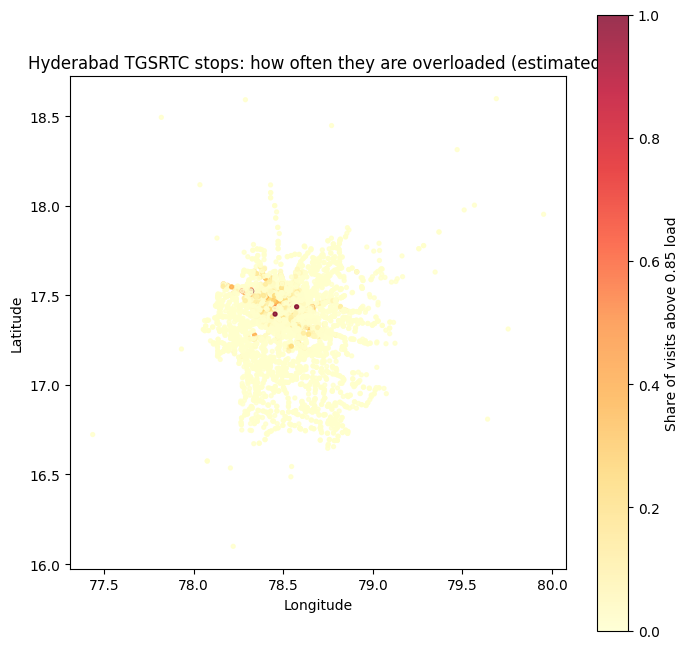

Saved fig_stop_map_overload.png


In [ ]:
import os
import matplotlib.pyplot as plt

os.makedirs("/content/figures", exist_ok=True)

plt.figure(figsize=(8, 8))
sc = plt.scatter(stop_stats["stop_lon"], stop_stats["stop_lat"],
                 c=stop_stats["overload_rate"], cmap="YlOrRd",
                 s=8, alpha=0.8)
plt.colorbar(sc, label="Share of visits above 0.85 load")
plt.title("Hyderabad TGSRTC stops: how often they are overloaded (estimated)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.gca().set_aspect("equal")
plt.savefig("/content/figures/fig_stop_map_overload.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved fig_stop_map_overload.png")

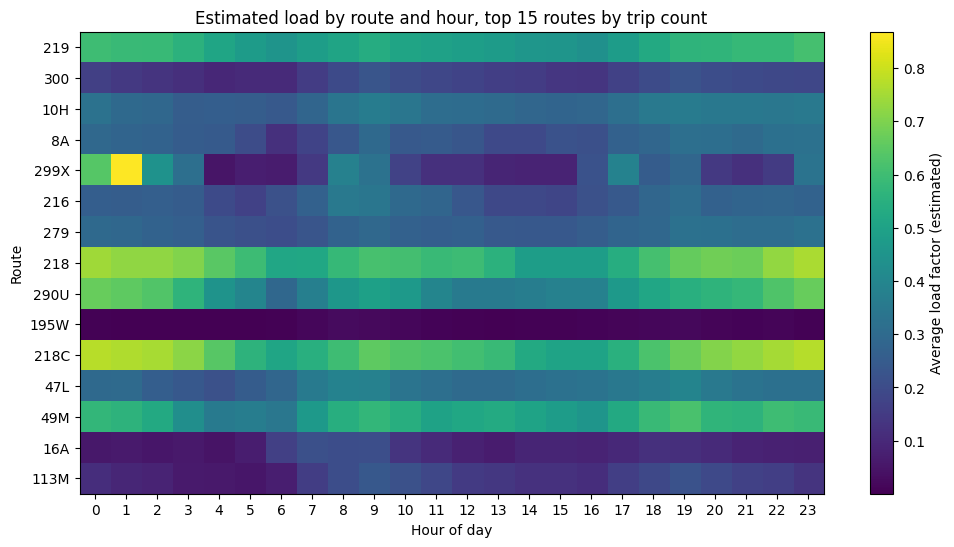

Saved fig_route_hour_heatmap.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

os.makedirs("/content/figures", exist_ok=True)

# Pick the 15 routes with the most trips
top_routes = [r["route_id"] for r in (df_real.groupBy("route_id")
              .agg(F.countDistinct("trip_id").alias("n"))
              .orderBy(F.desc("n")).limit(15).collect())]

heat = (df_real.filter(F.col("route_id").isin(top_routes))
    .withColumn("hour_of_day", F.col("hour") % 24)
    .groupBy("route_id", "hour_of_day")
    .agg(F.avg("load_factor").alias("avg_load"))
    .toPandas()
    .pivot(index="route_id", columns="hour_of_day", values="avg_load")
    .reindex(top_routes))

plt.figure(figsize=(12, 6))
im = plt.imshow(heat.values, aspect="auto", cmap="viridis")
plt.colorbar(im, label="Average load factor (estimated)")
plt.yticks(range(len(heat.index)), heat.index)
plt.xticks(range(24), range(24))
plt.xlabel("Hour of day")
plt.ylabel("Route")
plt.title("Estimated load by route and hour, top 15 routes by trip count")
plt.savefig("/content/figures/fig_route_hour_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved fig_route_hour_heatmap.png")

In [18]:
stop_stats = (
    df_real
    .groupBy("stop_id")
    .agg(
        F.count("*").alias("visits"),
        F.avg("load_factor").alias("avg_load"),
        F.avg(F.col("overloaded").cast("int")).alias("overload_rate")
    )
    .join(
        gtfs["stops"].select("stop_id", "stop_name", "stop_lat", "stop_lon"),
        on="stop_id"
    )
    .toPandas()
)

print(len(stop_stats), "stops with data")


5028 stops with data


In [19]:
import os
from pyspark.sql import functions as F

os.makedirs("/content/exports", exist_ok=True)

# Stop-level table for the Looker Studio map
stops_out = stop_stats.rename(columns={
    "visits": "stop_visits",
    "avg_load": "avg_load_factor",
    "overload_rate": "overloaded_share",
}).copy()

# Looker Studio map location format: latitude,longitude
stops_out["location"] = (
    stops_out["stop_lat"].astype(float).map(lambda x: f"{x:.6f}")
    + ","
    + stops_out["stop_lon"].astype(float).map(lambda x: f"{x:.6f}")
)

# Save a separate CSV for the map.
# This does not change hyderabad_hour_summary.csv.
map_csv = "/content/exports/stop_load_summary.csv"
stops_out.to_csv(map_csv, index=False)

# Keep the notebook's existing route-by-hour export
route_hour = (
    df_real
    .withColumn("hour_of_day", F.col("hour") % 24)
    .groupBy("route_id", "hour_of_day")
    .agg(
        F.count("*").alias("stop_visits"),
        F.round(F.avg("load_factor"), 3).alias("avg_load_factor"),
        F.sum(F.col("overloaded").cast("int")).alias("overloaded_count")
    )
    .toPandas()
)

route_hour.to_csv("/content/exports/route_hour_load.csv", index=False)

print("Map CSV saved:", map_csv)
print("Stops in map CSV:", len(stops_out))
print("Route-hour rows:", len(route_hour))

display(stops_out[
    ["stop_name", "stop_lat", "stop_lon", "location",
     "stop_visits", "overloaded_share"]
].head())


Map CSV saved: /content/exports/stop_load_summary.csv
Stops in map CSV: 5028
Route-hour rows: 21019


,stop_name,stop_lat,stop_lon,location,stop_visits,overloaded_share
0,Lv Prasad Eye Hospital,17.424000,78.428000,"17.424000,78.428000",430,0.002326
1,Lb Nagar,17.343705,78.555529,"17.343705,78.555529",17,0.176471
2,Moulali,17.462386,78.561666,"17.462386,78.561666",589,0.000000
3,Ragannaguda,17.262394,78.585967,"17.262394,78.585967",774,0.000000
4,Hitech City (Cyber Towers),17.449951,78.382574,"17.449951,78.382574",882,0.014739
